In [19]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.metrics import root_mean_squared_error

In [10]:
df = pd.read_csv(r"C:\Users\PGCP-AI.STUDENTSDC\Desktop\Machine_Learning\Datasets\monthly-milk-production-pounds-p.csv")
df.head()

,Month,Milk
0,1962-01,589
1,1962-02,561
2,1962-03,640
3,1962-04,656
4,1962-05,727


In [11]:
y = df['Milk']

### Centered Rolling Mean

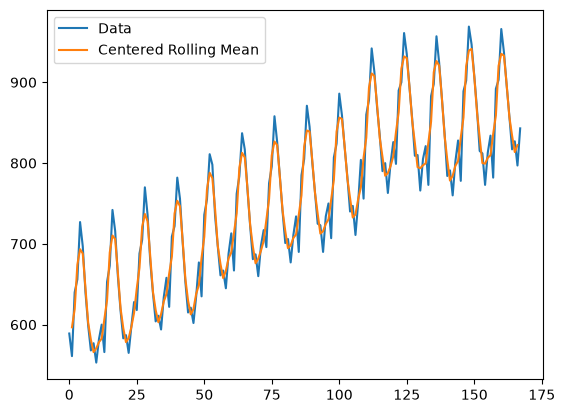

In [12]:
span = 3
fcast = y.rolling(span, center=True).mean()
plt.plot(y, label='Data')
plt.plot(fcast, label='Centered Rolling Mean')
plt.legend(loc='best')
plt.show()

### Trailing Rolling Mean

In [13]:
y_train = y[:-12]
y_test = y[-12:]

In [34]:
span = 3
fcast = y_train.rolling(span).mean()
MA = fcast.iloc[-1]
MA_Series = pd.Series(MA.repeat(len(y_test)))
MA_fcast = pd.concat([fcast,MA_Series],ignore_index=True)

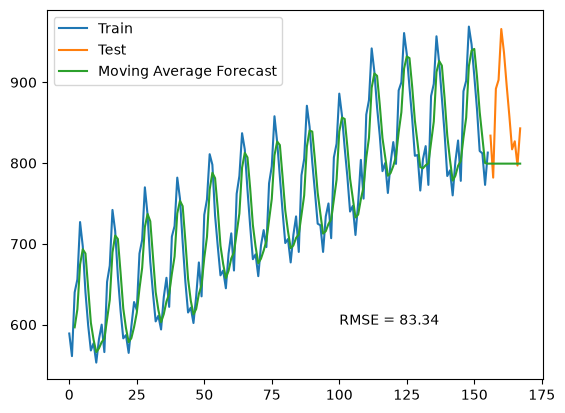

In [35]:
plt.plot(y_train, label='Train')
plt.plot(y_test, label='Test')
plt.plot(MA_fcast, label='Moving Average Forecast')
rmse = np.round(root_mean_squared_error(y_test,MA_Series),2)
plt.text(100,600,f'RMSE = {rmse}')
plt.legend(loc='best')
plt.show()

### Simple Exponential Smoothing 

In [37]:
from statsmodels.tsa.api import SimpleExpSmoothing

In [49]:
alpha = 0.2
ses = SimpleExpSmoothing(y_train,initialization_method='estimated')
fit1 = ses.fit(smoothing_level = alpha)
fcast1 = fit1.forecast(len(y_test))

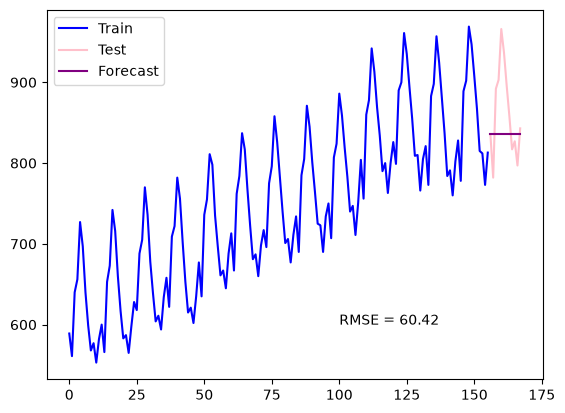

In [50]:
y_train.plot(color='blue', label='Train')
y_test.plot(color='pink', label='Test')
fcast1.plot(color='purple', label='Forecast')
plt.text(100,600, f'RMSE = {np.round(root_mean_squared_error(y_test,fcast1),2)}')
plt.legend(loc='best')
plt.show()

### Holt's Linear Trend Method

In [51]:
from statsmodels.tsa.api import Holt

In [55]:
alpha, beta = 0.1, 0.2
holt = Holt(y_train, initialization_method='estimated')
fit1 = holt.fit(smoothing_level = alpha, smoothing_trend=beta)
fcast1 = fit1.forecast(len(y_test))

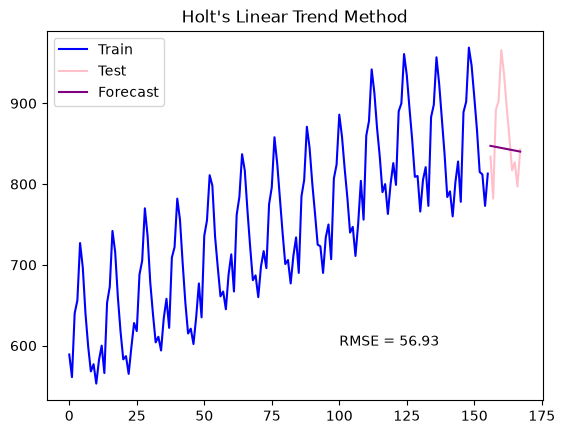

In [59]:
y_train.plot(color='blue', label='Train')
y_test.plot(color='pink', label='Test')
fcast1.plot(color='purple', label='Forecast')
plt.text(100,600, f'RMSE = {np.round(root_mean_squared_error(y_test,fcast1),2)}')
plt.legend(loc='best')
plt.title('Holt\'s Linear Trend Method')
plt.show()

### Holt's Exponential Smoothing 

In [60]:
alpha, beta = 0.1, 0.2
holt = Holt(y_train, initialization_method='estimated',exponential=True)
fit1 = holt.fit(smoothing_level = alpha, smoothing_trend=beta)
fcast1 = fit1.forecast(len(y_test))

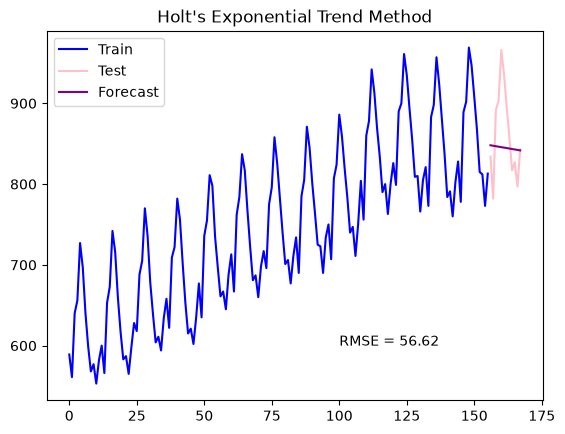

In [61]:
y_train.plot(color='blue', label='Train')
y_test.plot(color='pink', label='Test')
fcast1.plot(color='purple', label='Forecast')
plt.text(100,600, f'RMSE = {np.round(root_mean_squared_error(y_test,fcast1),2)}')
plt.legend(loc='best')
plt.title('Holt\'s Exponential Trend Method')
plt.show()

### Holt's Dumped Trend Method

In [63]:
alpha, beta, phi = 0.4, 0.2, 0.3
holt = Holt(y_train, initialization_method='estimated',damped_trend=True)
fit1 = holt.fit(smoothing_level = alpha, smoothing_trend=beta, damping_trend=phi, optimized=False)
fcast1 = fit1.forecast(len(y_test))

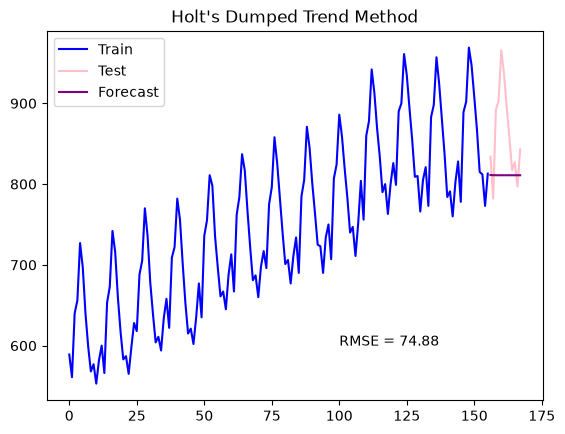

In [65]:
y_train.plot(color='blue', label='Train')
y_test.plot(color='pink', label='Test')
fcast1.plot(color='purple', label='Forecast')
plt.text(100,600, f'RMSE = {np.round(root_mean_squared_error(y_test,fcast1),2)}')
plt.legend(loc='best')
plt.title('Holt\'s Dumped Trend Method')
plt.show()

In [ ]:
### 

In [66]:
from statsmodels.tsa.api import ExponentialSmoothing

In [68]:
alpha, beta, gamma = 0.6, 0.2, 0.1
hw_add = ExponentialSmoothing(y_train, initialization_method='estimated',seasonal_periods=12, trend='add', seasonal='add')
fit1 = hw_add.fit(smoothing_level = alpha, smoothing_trend=beta, smoothing_seasonal=gamma)
fcast1 = fit1.forecast(len(y_test))

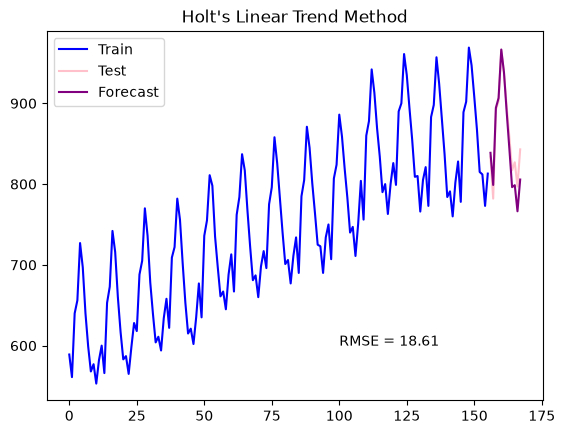

In [69]:
y_train.plot(color='blue', label='Train')
y_test.plot(color='pink', label='Test')
fcast1.plot(color='purple', label='Forecast')
plt.text(100,600, f'RMSE = {np.round(root_mean_squared_error(y_test,fcast1),2)}')
plt.legend(loc='best')
plt.title('Holt\'s Linear Trend Method')
plt.show()

In [70]:
alpha, beta, gamma = 0.6, 0.2, 0.1
hw_add = ExponentialSmoothing(y_train, initialization_method='estimated',seasonal_periods=12, trend='add', seasonal='add')
fit1 = hw_add.fit(smoothing_level = alpha, smoothing_trend=beta, smoothing_seasonal=gamma)
fcast1 = fit1.forecast(len(y_test))
alpha = fit1.params['smoothing_level']
beta = fit1.params['smoothing_trend']
gamma = fit1.params['smoothing_seasonal']

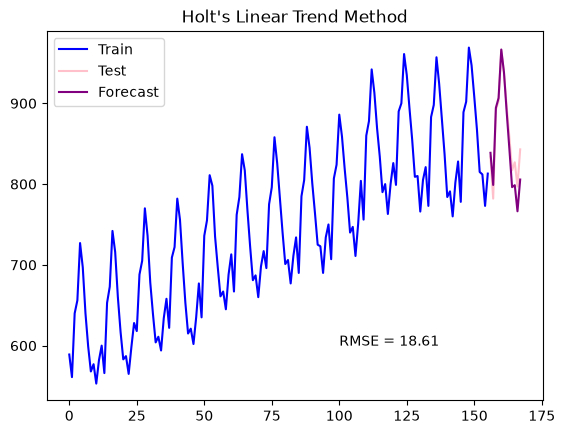

In [71]:
y_train.plot(color='blue', label='Train')
y_test.plot(color='pink', label='Test')
fcast1.plot(color='purple', label='Forecast')
plt.text(100,600, f'RMSE = {np.round(root_mean_squared_error(y_test,fcast1),2)}')
plt.legend(loc='best')
plt.title('Holt\'s Linear Trend Method')
plt.show()